# 3. If you can simulate it, you can fit it

A ball is dropped from two metres. Air drag slows it; the floor takes a fraction of its speed at every bounce. We measure the apex heights of the first three bounces: **0.955, 0.526 and 0.308 m**. Two dials are unknown: the restitution `e` and the drag `k`.

The simulator is 12 lines of C++ with a loop of 20,000 steps, a clamp and a branch (`kernel/ball.h`). No tracer enters it. Clad does, inside the compiler, and writes the gradient of a least-squares loss *through the whole simulation*. With that gradient, a standard optimiser finds both dials in a handful of steps.

In [1]:
import cppjit, numpy as np, time
cppjit.add_include_path("kernel"); cppjit.include("ball.h")
from kernel import derivatives; derivatives.load("ball")    # Clad writes the gradient of the loss, in the session
print(open("kernel/ball.h").read().split("#pragma once")[1])
g = cppjit.gbl.clad_generated


#include <cmath>
inline double apex(double e, double k, int n) {
  double y = 2.0, v = 0.0, dt = 1e-3, top = 0.0; int bounces = 0;
  for (int i = 0; i < 20000; ++i) {
    v -= (9.81 + k * v * std::fabs(v)) * dt;          // gravity and air drag
    y += v * dt;
    if (y < 0.0) { y = 0.0; v = -e * v; ++bounces; }  // the floor: a clamp and a branch
    if (bounces == n && v > 0.0 && y > top) top = y;  // the apex of bounce n
    if (bounces > n) break;
  }
  return top;
}
// p = {e, k}; obs = the apex heights of bounces 1..3
inline double loss(double* p, const double* obs) {
  double L = 0; for (int n = 1; n <= 3; ++n) { double d = apex(p[0], p[1], n) - obs[n-1]; L += d * d; } return L; }



[clad] loss_grad_0: generated by the Clad inside this kernel


## The measurements

Three apex heights. Here they come from the simulator itself at a hidden truth, `e = 0.80, k = 0.10`, so the fit can be checked; replace `obs` with heights you measured from a video of a real ball.

In [2]:
TRUE = (0.80, 0.10)
obs = np.array([cppjit.gbl.apex(TRUE[0], TRUE[1], n) for n in (1, 2, 3)])
print("observed apex heights (m):", np.round(obs, 4).tolist())
def L(p):  return float(cppjit.gbl.loss(np.ascontiguousarray(p, dtype=np.float64), obs))
def dL(p): d = np.zeros(2); g.loss_grad_0(np.ascontiguousarray(p, dtype=np.float64), obs, d); return d

observed apex heights (m): [0.955, 0.5259, 0.3078]


## Check the gradient before trusting it

Clad's gradient against central finite differences at a wrong starting point. The two agree to many digits; the finite difference needed 4 extra runs of the simulator and a guessed step size.

In [3]:
p0 = np.array([0.60, 0.30])
fd = np.array([(L(p0 + h) - L(p0 - h)) / (2 * 1e-6) for h in (np.array([1e-6, 0]), np.array([0, 1e-6]))])
t0 = time.perf_counter(); gr = dL(p0); t1 = time.perf_counter() - t0
print("Clad :", gr, f"  ({t1 * 1e3:.2f} ms, one call: value and both partials)"); print("FD   :", fd, f"  max rel diff {np.abs(gr - fd).max() / np.abs(fd).max():.1e}")

Clad : [-1.43449738  0.80292728]   (52.81 ms, one call: value and both partials)
FD   : [-1.43449738  0.80292728]   max rel diff 2.2e-10


## Fit it

SciPy's BFGS, given the loss and Clad's gradient. Every step the optimiser takes is recorded so we can draw the path.

In [4]:
from scipy.optimize import minimize
path = [p0.copy()]
t0 = time.perf_counter()
res = minimize(L, p0, jac=dL, method="BFGS", callback=lambda p: path.append(p.copy()), options={"gtol": 1e-10})
path = np.array(path)
print(f"e = {res.x[0]:.4f}  k = {res.x[1]:.4f}   (truth {TRUE[0]}, {TRUE[1]})   loss {res.fun:.2e}   {res.nit} iterations, {res.nfev} loss and {res.njev} gradient evaluations, {time.perf_counter() - t0:.2f} s")

e = 0.8000  k = 0.1000   (truth 0.8, 0.1)   loss 1.23e-29   10 iterations, 17 loss and 16 gradient evaluations, 0.05 s


## See it

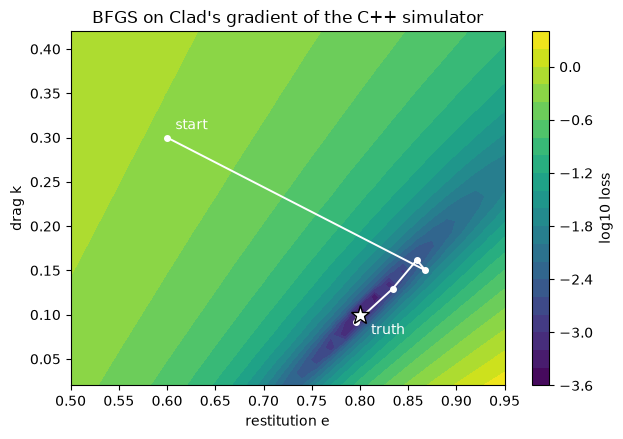

In [5]:
import matplotlib.pyplot as plt
E = np.linspace(0.5, 0.95, 31); Kd = np.linspace(0.02, 0.42, 29)
LL = np.array([[L(np.array([e, k])) for e in E] for k in Kd])
fig, ax = plt.subplots(figsize=(7, 4.6)); cs = ax.contourf(E, Kd, np.log10(LL + 1e-12), levels=24, cmap="viridis"); fig.colorbar(cs, label="log10 loss")
ax.plot(path[:, 0], path[:, 1], "-o", color="white", ms=4, lw=1.4); ax.plot(*TRUE, "*", color="white", ms=14, markeredgecolor="black")
ax.annotate("start", path[0], textcoords="offset points", xytext=(6, 6), color="white"); ax.annotate("truth", TRUE, textcoords="offset points", xytext=(8, -14), color="white")
ax.set_xlabel("restitution e"); ax.set_ylabel("drag k"); ax.set_title("BFGS on Clad's gradient of the C++ simulator"); plt.show()

## Keep your framework (optional, needs `pip install jax optimistix`)

The same loss as a JAX primitive whose backward pass is Clad's gradient, minimised by a JAX optimiser. JAX never sees the C++; it sees a function with a derivative. This is the "compose it" of the talk.

In [6]:
try:
    import jax, jax.numpy as jnp, optimistix as optx
    jax.config.update("jax_enable_x64", True)
    @jax.custom_vjp
    def loss_jax(p): return jax.pure_callback(lambda q: np.float64(L(np.asarray(q))), jax.ShapeDtypeStruct((), jnp.float64), p)
    loss_jax.defvjp(lambda p: jax.pure_callback(lambda q: (np.float64(L(np.asarray(q))), dL(np.asarray(q))), (jax.ShapeDtypeStruct((), jnp.float64), jax.ShapeDtypeStruct((2,), jnp.float64)), p), lambda gr, ct: (ct * gr,))
    sol = optx.minimise(lambda p, a: loss_jax(p), optx.BFGS(rtol=1e-10, atol=1e-12), jnp.asarray(p0), max_steps=200, throw=False)
    print("JAX/optimistix:", np.asarray(sol.value), "in", int(sol.stats["num_steps"]), "steps")
except ImportError:
    print("jax / optimistix not installed: skipped")

jax / optimistix not installed: skipped


## Play with it

- Add a fourth bounce to the loss (edit `kernel/ball.h`; Clad regenerates the gradient from the edited header on the next `derivatives.load`).
- Start the optimiser far away (`p0 = [0.95, 0.4]`) and watch the path.
- Replace `obs` with real measurements. Two numbers come out, with the loss telling you how well a ball with constant restitution and quadratic drag explains them.

Next: the same recipe on 28 real events from the LHC, `4_higgs_open_data.ipynb`.